In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mutual_info_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report, roc_curve, auc
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# import data
df = pd.read_csv('~/python/data/ml_zoomcamp/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
# Split numeric and categorical data
numeric = [col for col in df.columns if df[col].dtype != 'str']
numeric.remove('converted') # remove target
categorical = [col for col in df.columns if df[col].dtype == 'str']
print(numeric)
print(categorical)

['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
['lead_source', 'industry', 'employment_status', 'location']


In [5]:
# Fill na
df[numeric] = df[numeric].fillna(0.0)
df[categorical] = df[categorical].fillna('NA')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
print(df_train.shape, df_val.shape, df_test.shape)

(3000, 9) (1000, 9) (1000, 9)


### Question 1

Evaluate the feature importance for the numeric features using ROC AUC

In [7]:
# Print numeric training data
df_train[numeric]

,annual_income,number_of_courses_viewed,interaction_count,lead_score
4740,80198.0,5,9,0.91
1452,50548.0,2,5,0.48
2846,76300.0,0,3,0.42
4670,80371.0,2,6,0.49
168,73567.0,2,4,0.48
...,...,...,...,...
253,84573.0,2,3,0.37
1366,85051.0,1,3,0.56
753,21561.0,0,1,0.17
4990,31691.0,3,5,0.49


In [8]:
# Calculate auc for each numeric feature
for num in numeric:
    fpr, tpr, thresholds = roc_curve(df_train['converted'], df_train[num])
    area = auc(fpr, tpr)
    if area < 0.5:
        fpr, tpr, thresholds = roc_curve(df_train['converted'], -df_train[num])
        area = auc(fpr, tpr)
        print(f'AUC for {num}: {area}')
    else:
        print(f'AUC for {num}: {area}')


AUC for annual_income: 0.6081977776250831
AUC for number_of_courses_viewed: 0.7229894623989618
AUC for interaction_count: 0.7649203047563227
AUC for lead_score: 0.7882254810906102


### Question 2

Train the model. What is the AUC on the validation dataset?

In [10]:
# Split features and target
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [12]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numeric].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [13]:
# Evaluate model
val_dict = df_val[categorical + numeric].to_dict(orient='records')
X_val = dv.fit_transform(val_dict)
val_probs = model.predict_proba(X_val)[:,1]

fpr, tpr, thresholds = roc_curve(y_val, val_probs)
area = auc(fpr, tpr)
area

0.7318222288173319

### Question 3

Calculate precision and recall for all thresholds from 0-1 in steps of 0.01. Where do they intersect?

In [28]:
# Compute precision and recal on all thresholds
thresholds = np.arange(0, 1.01, 0.01)
tn = []
fn = []
fp = []
tp = []
precision = []
recall = []
for t in thresholds:
    probs = model.predict_proba(X_val)[:,1]
    preds = (probs > t).astype(int)
    cm = confusion_matrix(y_val, preds)

    tn.append(cm[0,0])
    fn.append(cm[1,0])
    fp.append(cm[0,1])
    tp.append(cm[1,1])

    prec = cm[1,1]/np.where((cm[1,1]+cm[0,1]) == 0, 1, cm[1,1]+cm[0,1])
    rec = cm[1,1]/np.where((cm[1,1]+cm[1,0]) == 0, 1, cm[1,1]+cm[1,0])

    precision.append(prec)
    recall.append(rec)

In [29]:
# Put data into dataframe
tdf = pd.DataFrame(
    {
        'thresholds': thresholds,
        'TN': tn,
        'FN': fn,
        'FP': fp,
        'TP': tp,
        'precision': precision,
        'recall': recall
    }
)
tdf

,thresholds,TN,FN,FP,TP,precision,recall
0,0.00,0,0,414,586,0.586,1.000000
1,0.01,0,0,414,586,0.586,1.000000
2,0.02,0,0,414,586,0.586,1.000000
3,0.03,0,0,414,586,0.586,1.000000
4,0.04,0,0,414,586,0.586,1.000000
...,...,...,...,...,...,...,...
96,0.96,414,585,0,1,1.000,0.001706
97,0.97,414,586,0,0,0.000,0.000000
98,0.98,414,586,0,0,0.000,0.000000
99,0.99,414,586,0,0,0.000,0.000000


Text(0, 0.5, 'Measure')

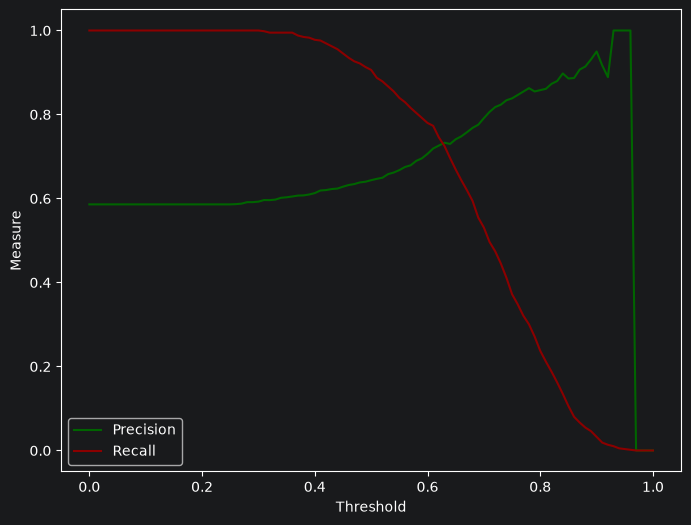

In [31]:
# plot results
plt.figure(figsize=(8,6))

plt.plot(tdf['thresholds'], tdf['precision'], label='Precision', color='darkgreen')
plt.plot(tdf['thresholds'], tdf['recall'], label='Recall', color='darkred')

plt.legend()
plt.xlabel('Threshold')
plt.ylabel('Measure')

In [38]:
# absolute difference
tdf['diff'] = np.abs(tdf['precision'] - tdf['recall'])
tdf[(tdf['thresholds'] < 0.7) & (tdf['thresholds'] > 0.6)]

,thresholds,TN,FN,FP,TP,precision,recall,diff,F1
61,0.61,237,133,177,453,0.719048,0.773038,0.053990,0.745066
62,0.62,249,149,165,437,0.725914,0.745734,0.019820,0.735690
63,0.63,259,161,155,425,0.732759,0.725256,0.007503,0.728988
64,0.64,263,178,151,408,0.729875,0.696246,0.033629,0.712664
65,0.65,277,194,137,392,0.741021,0.668942,0.072079,0.703139
66,0.66,287,209,127,377,0.748016,0.643345,0.104671,0.691743
67,0.67,298,223,116,363,0.757829,0.619454,0.138375,0.681690
68,0.68,309,238,105,348,0.768212,0.593857,0.174355,0.669875
69,0.69,320,261,94,325,0.775656,0.554608,0.221049,0.646766


### Question 4

Compute the F1 score for all the above threholds

Text(0, 0.5, 'Measure')

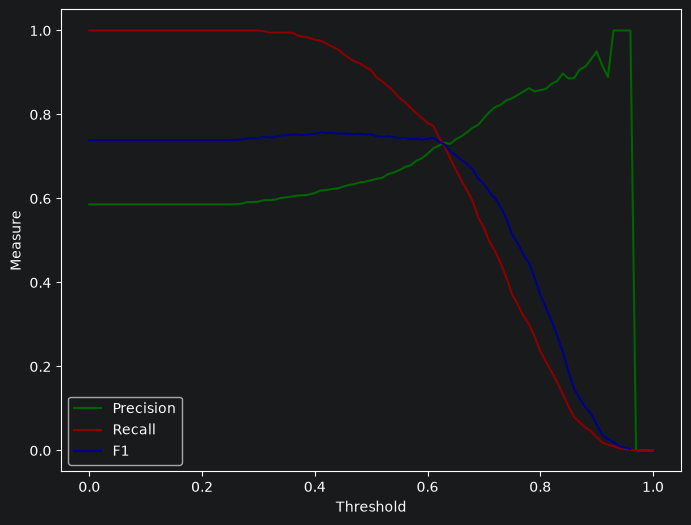

In [35]:
# Compute F1
tdf['F1'] = 2*(tdf['precision'] * tdf['recall'])/(tdf['precision'] + tdf['recall'])

# plot results
plt.figure(figsize=(8,6))

plt.plot(tdf['thresholds'], tdf['precision'], label='Precision', color='darkgreen')
plt.plot(tdf['thresholds'], tdf['recall'], label='Recall', color='darkred')
plt.plot(tdf['thresholds'], tdf['F1'], label='F1', color='darkblue')

plt.legend()
plt.xlabel('Threshold')
plt.ylabel('Measure')

In [36]:
# Get row where F1 is max
tdf[tdf['F1'] == max(tdf['F1'])]

,thresholds,TN,FN,FP,TP,precision,recall,diff,F1
41,0.41,62,14,352,572,0.619048,0.976109,0.357062,0.757616


### Question 5

Use KFold validation with K=5 to train the model. How large is the standard deviation of the scores across the folds?

In [44]:
def train(df_train, y_train):
    dicts = df_train[categorical + numeric].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
     dicts = df[categorical + numeric].to_dict(orient='records')

     X = dv.fit_transform(dicts)
     y_pred = model.predict_proba(X)[:,1]

     return y_pred

In [48]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [49]:
np.std(scores)

0.006853233151022138

### Question 6

 Optimise the hyperparameter C from the list [0.000001, 0.001, 1]

In [50]:
def train(df_train, y_train, C):
    dicts = df_train[categorical + numeric].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
     dicts = df[categorical + numeric].to_dict(orient='records')

     X = dv.fit_transform(dicts)
     y_pred = model.predict_proba(X)[:,1]

     return y_pred

In [53]:
C = [0.000001, 0.001, 1]
means = []
stds = []
for c in C:

    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        dv, model = train(df_train, y_train, c)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    means.append(np.round(np.mean(scores), 3))
    stds.append(np.round(np.std(scores), 3))

In [54]:
means, stds

([0.617, 0.749, 0.732], [0.019, 0.01, 0.007])